# 04 - Repayment regression (SYNTHETIC data)
**Target:** `repayment_ratio_6` = paid amount / due amount over a loan's first 6 instalments (0..1). 1.0 = every instalment fully paid by the snapshot.
**Population:** loans with >= 9 months on book (so late payers have had time to pay) and all 6 instalment rows present.
**Features:** origination-time only (same list as the default model). **Split:** out-of-time (train <= 2025-01-31, test later).
**Metrics:** MAE, RMSE, R-squared. Baseline = predict the training mean.
The target is heavily concentrated at 1.0 (most loans pay everything), so R-squared is expected to be modest; we also report error on the at-risk tail.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score

from src.data_access import load_tables
from src.analytics.common import setup, save_fig, save_results, banner
from src.modelling import features as F

setup(); banner()
SEED = 42
t = load_tables()
data = F.repayment_dataset(t)
train, test = F.temporal_split(data, F.TRAIN_END_REPAY)
Xtr, ytr, Xte, yte = train[F.FEATURES], train.repayment_ratio_6, test[F.FEATURES], test.repayment_ratio_6
print(f"train {len(train)} ({train.disbursement_date.min().date()}..{train.disbursement_date.max().date()}), test {len(test)} ({test.disbursement_date.min().date()}..{test.disbursement_date.max().date()})")
print(f"target: mean {data.repayment_ratio_6.mean():.3f}, median {data.repayment_ratio_6.median():.3f}, share == 1.0: {(data.repayment_ratio_6 >= 0.9999).mean():.1%}, share < 0.5: {(data.repayment_ratio_6 < 0.5).mean():.1%}")
res = dict(train_n=len(train), test_n=len(test), target_mean=float(data.repayment_ratio_6.mean()), share_full=float((data.repayment_ratio_6 >= 0.9999).mean()))

ALL DATA IN THIS PROJECT IS SYNTHETIC. Findings describe the simulation, not real lending.


[data] loaded from PostgreSQL (analytics schema)
train 8773 (2023-07-01..2025-01-31), test 5572 (2025-02-01..2025-09-30)
target: mean 0.952, median 1.000, share == 1.0: 92.6%, share < 0.5: 4.8%


In [2]:
models = {
    "Baseline (train mean)": Pipeline([("pre", F.make_preprocessor(False)), ("m", DummyRegressor(strategy="mean"))]),
    "Ridge regression": Pipeline([("pre", F.make_preprocessor(True)), ("m", Ridge(alpha=10.0))]),
    "Random forest": Pipeline([("pre", F.make_preprocessor(False)), ("m", RandomForestRegressor(n_estimators=300, min_samples_leaf=25, n_jobs=-1, random_state=SEED))]),
    "Gradient boosting": Pipeline([("pre", F.make_preprocessor(False)), ("m", HistGradientBoostingRegressor(learning_rate=0.05, max_iter=200, max_leaf_nodes=8, min_samples_leaf=40, l2_regularization=1.0, random_state=SEED))]),
}
rows, preds = [], {}
tail = yte < 0.8       # at-risk loans: paid less than 80% of the first 6 instalments
for name, pipe in models.items():
    cv_r2 = cross_val_score(clone(pipe), Xtr, ytr, cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2").mean()
    pipe.fit(Xtr, ytr)
    p = np.clip(pipe.predict(Xte), 0, 1)
    preds[name] = p
    rows.append(dict(model=name, MAE=mean_absolute_error(yte, p), RMSE=np.sqrt(mean_squared_error(yte, p)), R2=r2_score(yte, p), R2_train_cv=cv_r2,
                     MAE_on_atrisk_tail=mean_absolute_error(yte[tail], p[tail])))
metrics = pd.DataFrame(rows).set_index("model")
print(metrics.round(4))
res["metrics"] = metrics.round(5).to_dict("index")
res["atrisk_share_test"] = float(tail.mean())
best = metrics.drop("Baseline (train mean)").R2.idxmax()
res["best_model"] = best
print("Best by test R2:", best)

                          MAE    RMSE      R2  R2_train_cv  MAE_on_atrisk_tail
model                                                                         
Baseline (train mean)  0.0899  0.1943 -0.0015      -0.0011              0.6609
Ridge regression       0.0829  0.1854  0.0882       0.0787              0.6032
Random forest          0.0787  0.1860  0.0817       0.0898              0.5994
Gradient boosting      0.0779  0.1862  0.0804       0.0783              0.5986
Best by test R2: Ridge regression


## Predicted vs actual and residuals

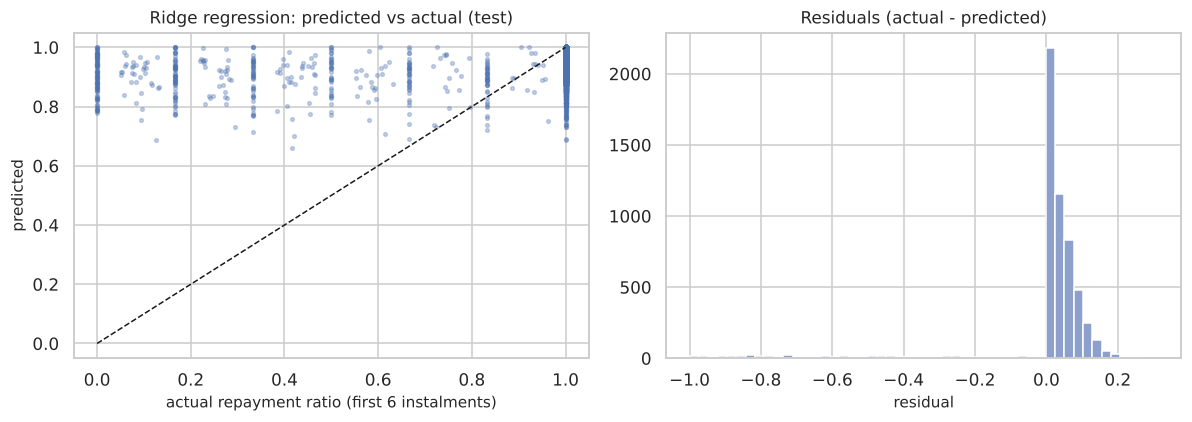

    pred  actual
q               
0  0.875   0.852
1  0.937   0.943
2  0.964   0.971
3  0.988   0.979
4  1.000   0.993


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(yte, preds[best], s=6, alpha=0.3, color="#4c72b0"); axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("actual repayment ratio (first 6 instalments)"); axes[0].set_ylabel("predicted"); axes[0].set_title(f"{best}: predicted vs actual (test)")
axes[1].hist(yte - preds[best], bins=50, color="#8da0cb"); axes[1].set_title("Residuals (actual - predicted)"); axes[1].set_xlabel("residual")
save_fig(fig, "ml_repayment_pred_vs_actual")
# calibration by predicted quintile
q = pd.qcut(pd.Series(preds[best]).rank(method="first"), 5, labels=False)
cal = pd.DataFrame({"q": q.values, "pred": preds[best], "act": yte.values}).groupby("q").agg(pred=("pred", "mean"), actual=("act", "mean"))
print(cal.round(3)); res["quintile_calibration"] = cal.round(4).reset_index().to_dict("records")

## Limitations
* Target is bounded and zero-inflated/one-inflated: a plain regression can predict outside [0, 1] (we clip) - a two-part or beta-regression model would be more principled.
* Predictions are about the **first 6 instalments** only, from origination-time data; behaviour after disbursement (e.g. first missed payment) would add power but would no longer be an origination-time model.
* Synthetic data: modest R-squared here reflects the simulator's noise level, not a real benchmark. Association, not causation.
save_results("ml_repayment", res)